# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot March and September Alaskan regional SIC for 1980-2020 and villages

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick

## Load Model data
- regional, monthly data by decade

### Get grid data

In [2]:
# load grid files for plotting

dir_grid = '/glade/u/home/duvivier/masks/'
file_in = 'POP_tx0.1v3_grid.nc'
ds_grid = xr.open_mfdataset(dir_grid+file_in, decode_times=False)    

# clip global data to match other files - do in two steps because that's how I originally clipped data
# Step 1: clip to full Arctic Region
ds_grid_sub = ds_grid.isel(nlat=slice(1750,2400))
# Step 2: clip Arctic Region to Pacific sector only
ds_grid_sub = ds_grid_sub.isel(nlon=slice(2500,3250))

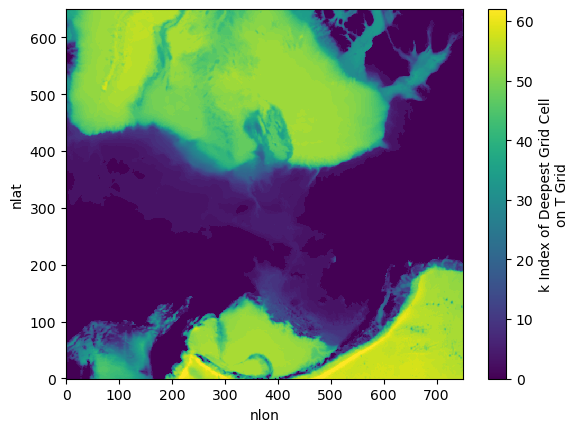

In [3]:
ds_grid_sub.KMT.plot()

In [4]:
# grab lat and lon data
cesm_lat2d = ds_grid_sub.TLAT
cesm_lon2d = ds_grid_sub.TLONG

### Get Model SIC data
- Model monthly data by decade (1920-29, 1950-59, 1980-89, 2010-2019) - has been preprocessed

In [5]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/mesaclip_validation/'
fin = 'mesaclip_sic_march_steptember_alaska_region.nc'

ds = xr.open_dataset(dir_in+fin)

In [6]:
ds

<xarray.Dataset> Size: 20MB
Dimensions:       (nj: 650, ni: 750)
Dimensions without coordinates: nj, ni
Data variables:
    sic_mar_1920  (nj, ni) float32 2MB ...
    sic_mar_1950  (nj, ni) float32 2MB ...
    sic_mar_1980  (nj, ni) float32 2MB ...
    sic_mar_2010  (nj, ni) float32 2MB ...
    sic_mar_hist  (nj, ni) float32 2MB ...
    sic_sep_1920  (nj, ni) float32 2MB ...
    sic_sep_1950  (nj, ni) float32 2MB ...
    sic_sep_1980  (nj, ni) float32 2MB ...
    sic_sep_2010  (nj, ni) float32 2MB ...
    sic_sep_hist  (nj, ni) float32 2MB ...
Attributes:
    author:          Alice DuVivier
    date_processed:  2026-07-06
    contents:        MESACLIP Arctic sea ice for validation

In [7]:
# load data - historical is 1980-2020 mean
cesm_mar_hist = ds.sic_mar_hist
cesm_sep_hist = ds.sic_sep_hist

## Load CDR satellite SIC data
- daily NH data on 25km x 25km grid

### Get grid data

In [8]:
# load grid files for plotting

dir_grid = '/glade/campaign/cesm/development/pcwg/ssmi/'
file_in = 'grid_nh.nc'
ds_grid = xr.open_mfdataset(dir_grid+file_in, decode_times=False)    

In [9]:
ds_grid

<xarray.Dataset> Size: 2MB
Dimensions:     (ygrid: 448, xgrid: 304)
Coordinates:
  * xgrid       (xgrid) float32 1kB -3.838e+06 -3.812e+06 ... 3.738e+06
  * ygrid       (ygrid) float32 2kB 5.838e+06 5.812e+06 ... -5.338e+06
Data variables:
    latitude    (ygrid, xgrid) float64 1MB dask.array<chunksize=(448, 304), meta=np.ndarray>
    longitude   (ygrid, xgrid) float64 1MB dask.array<chunksize=(448, 304), meta=np.ndarray>
    projection  |S182 182B ...
Attributes: (12/43)
    Conventions:               CF-1.6
    title:                     NOAA/NSIDC Climate Data Record of Passive Micr...
    references:                Comiso, J. C., and F. Nishio. 2008. Trends in ...
    cdr_program:               NOAA Climate Data Record Program
    cdr_variable:              seaice_conc_cdr
    software_version_id:       svn+ssh://newice.colorado.edu/SubversionReposi...
    ...                        ...
    sensor:                    SMMR > Scanning Multichannel Microwave Radiometer
    date_created:              2013-05-22T19:11:43Z
    time_coverage_start:       1979-01-02T00:00:00Z
    time_coverage_end:         1979-01-02T23:59:59Z
    comment:                   The variables seaice_conc_cdr, stdev_of_seaice...
    nco_openmp_thread_number:  1

In [10]:
# grab lat and lon data
cdr_lat2d = ds_grid.latitude
cdr_lon2d = ds_grid.longitude

### Get CDR SIC data
- Satellite monthly data averaged from daily to monthly over historical (1980-2020)

In [11]:
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/mesaclip_validation/'
file_in = 'cdr_sic_march_steptember_alaska_region.nc'

ds_cdr = xr.open_dataset(dir_in + file_in)

In [12]:
ds_cdr

<xarray.Dataset> Size: 1MB
Dimensions:       (jdim: 448, idim: 304)
Coordinates:
  * jdim          (jdim) float32 2kB 5.838e+06 5.812e+06 ... -5.338e+06
  * idim          (idim) float32 1kB -3.838e+06 -3.812e+06 ... 3.738e+06
Data variables:
    sic_mar_hist  (jdim, idim) float32 545kB ...
    sic_sep_hist  (jdim, idim) float32 545kB ...
Attributes:
    author:          Alice DuVivier
    date_processed:  2026-07-06
    contents:        CDR satellite Arctic sea ice for validation

In [13]:
# rename cdr data dimensions jdim to ygrid and idim to xgrid to match grid data
ds_cdr = ds_cdr.rename({"jdim": "ygrid", "idim": "xgrid"})

In [14]:
# load data - historical is 1980-2020 mean
cdr_mar_hist = ds_cdr.sic_mar_hist
cdr_sep_hist = ds_cdr.sic_sep_hist

In [15]:
# in september, mask some data from a patch of low concentration near nome
cdr_sep_hist = cdr_sep_hist.where(cdr_lat2d >= 65, 0)

## Plot Maps by decade and month to compare

In [16]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

In [17]:
# set lat/lon bounds
lat_max = 75
lat_min = 50
lon_max = 220
lon_min = 170
lon_avg = 200.0

In [18]:
# set ice edge line for overlay contour plot
levels_ice = [15,100]

In [19]:
# set paired lists with name and lat/lon
# main villages
village_names_1 = ['Shishmaref','Nome','Unalakleet','Savoonga','Gambell']
village_lats_1 =  [66.257, 64.501, 63.879, 63.694,63.77611]
village_lons_1 =  [-166.072, -165.406, -160.790, -170.479,-171.70083]

# other villages names - 
# Utqiagvik, Wrainwright, Point Lay, Point Hope, Kivalina, Kotzebue, Deering, Wales, Teller, Brevig Mission, 
# Solomon, Golovin, Elim, Koyuk, Shaktoolik, St. Michaels, Stebbins, Kotlik, Emmonak, Alakanuk
# Nunam Iqua, Scammon Bay, Paimiut, Hooper Bay, Chevak, Newtok, Tununak, Umkumiut, Nunakauyarmiut
# Nightmute, Chefornak, Kipnuk, Kwigillingok, Kongiganak, Tuntutuliak, Eek, Kwinhagak, Platinum, Goodnews Bay, Togiak,
# Aleut Community of St. Paul, Aleut Community of St. George, Mekoryuk, King Island, Little Diomede Island
village_lats_2 =  [71.29,70.638,69.7438,68.347052,67.7272,66.898331,66.07583,65.61222,65.26349,65.3347,\
                   64.55876,64.54333,64.6178,64.9311,64.3556,63.478526,63.51194,63.0358,62.7722,62.68889,\
                   62.516094,61.8425,61.70083,61.531111,61.52778,60.9428,60.5805,60.4996528,60.53381,\
                   60.49139,60.15907,59.9390,59.872266,59.953896,60.3426,60.218662,59.753374,59.008483,59.121408,59.06194,\
                   57.1250,56.60556,60.389278,64.9750,65.754]
village_lons_2 =  [-156.79,-160.033,-163.0084,-166.762917,-164.5392,-162.596664,-162.71833,-168.08917,-166.36244,-166.4892,\
                   -164.44327,-163.02917,-162.2567,-161.1586,-161.1913,-162.037123,-162.27472,-163.5603,-164.5450,-164.61528,\
                   -164.895198,-165.5817,-165.83861,-166.096667,-165.57861,-164.6311,-165.2595,-165.1988583,-165.10374,\
                   -164.82611,-164.269437,-164.0370,-163.166165,-162.895199,-162.6727,-162.025928,-161.902701,-161.814750,-161.585835,-160.37639,\
                   -170.2708,-169.55972,-166.207082,-168.0597,-168.921]

nvillages_1 = len(village_names_1)
nvillages_2 = len(village_lats_2)

### Create map plots

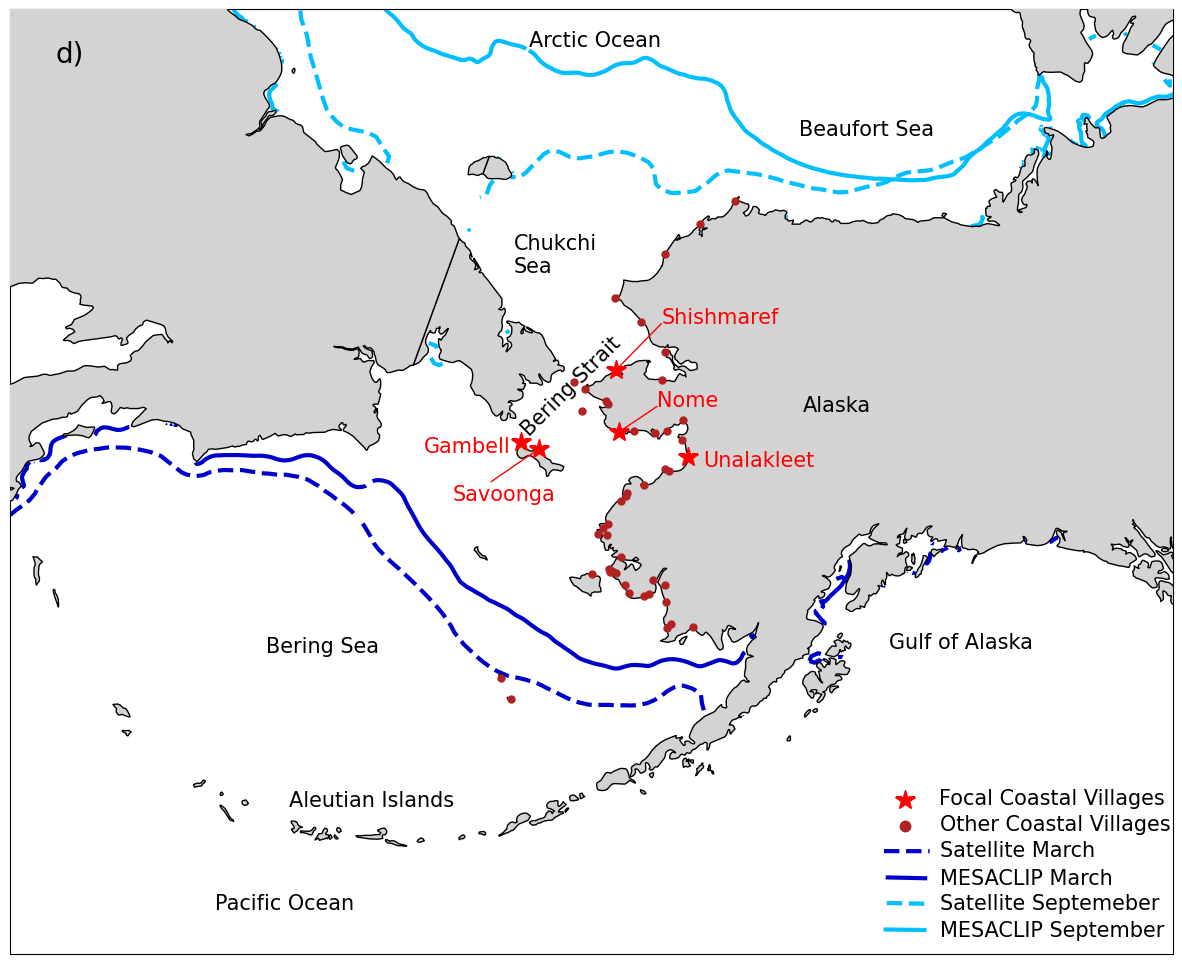

In [30]:
### Plot village locations
# create figure
fig = plt.figure(figsize=(15,15))
fout = 'fig_1_sic_map'

fs = 15
# Make subplots - note it's nrow x ncol x index (starting upper left)
### First subplot: Alaska
ax = fig.add_subplot(1,1,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
ax.set_extent([lon_min, lon_max, lat_max, lat_min], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k',facecolor='lightgrey')

# add sea ice
# MESACLIP - March
data_masked = np.ma.masked_where(np.abs(np.diff(cesm_lon2d, axis=1)) > 180,cesm_mar_hist[:, :-1])
cs1 = ax.contour(cesm_lon2d[:, :-1], cesm_lat2d[:, :-1], data_masked, colors='mediumblue',linestyles='solid',linewidths=3,levels=levels_ice,transform=ccrs.PlateCarree())    
# CDR - March
data_masked = np.ma.masked_where(np.abs(np.diff(cdr_lon2d, axis=1)) > 180,cdr_mar_hist[:, :-1])
cs2 = ax.contour(cdr_lon2d[:, :-1], cdr_lat2d[:, :-1], data_masked, colors='mediumblue',linestyles='dashed',linewidths=3,levels=levels_ice,transform=ccrs.PlateCarree())
# MESACLIP - September
data_masked = np.ma.masked_where(np.abs(np.diff(cesm_lon2d, axis=1)) > 180,cesm_sep_hist[:, :-1])
cs1 = ax.contour(cesm_lon2d[:, :-1], cesm_lat2d[:, :-1], data_masked, colors='deepskyblue',linestyles='solid',linewidths=3,levels=levels_ice,transform=ccrs.PlateCarree())    
# CDR - September
data_masked = np.ma.masked_where(np.abs(np.diff(cdr_lon2d, axis=1)) > 180,cdr_sep_hist[:, :-1])
cs2 = ax.contour(cdr_lon2d[:, :-1], cdr_lat2d[:, :-1], data_masked, colors='deepskyblue',linestyles='dashed',linewidths=3,levels=levels_ice,transform=ccrs.PlateCarree())

# add place names text
ax.text(207.0, 65.0, s='Alaska',fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(180.0, 49.0, s='Pacific Ocean',fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(181.5, 52.25, s='Aleutian Islands',fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(210.0, 58.0, s='Gulf of Alaska',fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(178.0, 56.0, s='Bering Sea',fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(188.0, 63.95, s='Bering Strait',rotation=45, fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(185.0, 68.5, s='Chukchi\nSea',fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(210.0, 73.0, s='Beaufort Sea',fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(180.0, 75.0, s='Arctic Ocean',fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())

# add primary village locations and names
ax.plot(village_lons_1, village_lats_1, marker="*", markersize=15, linestyle='none', color='red',zorder=100,transform=ccrs.PlateCarree())
# add labels for primary villages
ax.text(-163.0,67.7,"Shishmaref",fontsize=fs,color='red',zorder=100,transform=ccrs.PlateCarree())
ax.plot([-166.072,-163.0],[66.257,67.7], color='red', linewidth=1, marker='none', zorder=100, transform=ccrs.PlateCarree())
ax.text(-163.0,65.3,"Nome",fontsize=fs,color='red',zorder=100,transform=ccrs.PlateCarree())
ax.plot([-165.406,-163.0],[64.501,65.3], color='red', linewidth=1, marker='none', zorder=100,transform=ccrs.PlateCarree())
ax.text(-159.8,63.6,"Unalakleet",fontsize=fs,color='red',zorder=100,transform=ccrs.PlateCarree())
ax.text(-175.0,61.7,"Savoonga",fontsize=fs,color='red',zorder=100,transform=ccrs.PlateCarree())
ax.plot([-173.0,-170.479],[62.5,63.694], color='red', linewidth=1, marker='none', zorder=100,transform=ccrs.PlateCarree())
ax.text(-177.5,62.8,"Gambell",fontsize=fs,color='red',zorder=100,transform=ccrs.PlateCarree())

# add secondary village locations
ax.plot(village_lons_2, village_lats_2, marker=".", markersize=10, linestyle='none', color='firebrick',zorder=100,transform=ccrs.PlateCarree())

# add a legend
ax.text(211.0,53.5, s='Focal Coastal Villages', fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.plot(209.5,53.8, marker="*", markersize=15, linestyle='none', color='red',zorder=100,transform=ccrs.PlateCarree())
ax.text(210.8,52.8, s='Other Coastal Villages', fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.plot(209.3,53.1, marker=".", markersize=15, linestyle='none', color='firebrick',zorder=100,transform=ccrs.PlateCarree())
ax.text(210.6,52.1, s='Satellite March', fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.plot([208.2,210.2],[52.5,52.3], color='mediumblue', linewidth=3, linestyle='dashed', marker='none', zorder=100, transform=ccrs.PlateCarree())
ax.text(210.4,51.35, s='MESACLIP March', fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.plot([208.2,209.8],[51.78,51.6], color='mediumblue', linewidth=3, linestyle='solid', marker='none', zorder=100, transform=ccrs.PlateCarree())
ax.text(210.2,50.7, s='Satellite Septemeber', fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.plot([208.0,209.8],[51.1,50.9], color='deepskyblue', linewidth=3, linestyle='dashed', marker='none', zorder=100, transform=ccrs.PlateCarree())
ax.text(210.0,50.0, s='MESACLIP September', fontsize=fs,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.plot([207.8,209.4],[50.4,50.23], color='deepskyblue', linewidth=3, linestyle='solid', marker='none', zorder=100, transform=ccrs.PlateCarree())


# add label
ax.text(147.0,66.0,"d)",fontsize=20,color='black',zorder=100,transform=ccrs.PlateCarree())

# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)